# Example 4: Diabatic–adiabatic state transfer in a four-level system

Authors: C. Ventura-Meinersen and D. Fernandez-Fernandez

Below we import the necessary libraries for this example file:

In [1]:
import numpy as np

import geodesiq as gq

# Four-level model

Two coupled sites, left ($L$) and right ($R$), each have a local ground state $\ket{g}$ and excited state $\ket{e}$. In the basis $\{\ket{L,e},\ket{L,g},\ket{R,e},\ket{R,g}\}$, the Hamiltonian reads
$$\hat{H}[\varepsilon(t)] =
\begin{pmatrix}
    \varepsilon/2+\Delta_L & 0 & t_{ee} & t_{eg} \\
    0 & \varepsilon/2-\Delta_L & t_{ge} & t_{gg} \\
    t_{ee}^* & t_{ge}^* & -\varepsilon/2+\Delta_R & 0 \\
    t_{eg}^* & t_{gg}^* & 0 & -\varepsilon/2-\Delta_R
\end{pmatrix},$$
with $t_{ee}=\frac{t_c}{2}[1+e^{i(\phi_L-\phi_R)}]$, $t_{eg}=\frac{t_c}{2}(e^{i\phi_L}-e^{i\phi_R})$, $t_{gg}=t_{ee}^*$ and $t_{ge}=-t_{eg}^*$. We use $\Delta_R=2\Delta_L$, $t_c=0.2\Delta_L$, $\phi_L=0.1$ and $\phi_R=\pi/2$, in units of $\Delta_L=1$.

The detuning is swept from $\varepsilon(0)=-12\Delta_L$ to $\varepsilon(t_\text{f})=12\Delta_L$. Labeling the instantaneous eigenstates by increasing energy, starting from zero, the task is to connect $\ket{\psi_1}$ to $\ket{\psi_2}$. The first anticrossing (near $\varepsilon=-3\Delta_L$) must be passed diabatically, and the later ones adiabatically. Setting `final_state=2` (different from `initial_state=1`) selects the diabatic–adiabatic (di–ad) tensor, whose diabatic exponents are `dia_alpha` and `dia_beta`.

In [2]:
def four_level_hamiltonian(eps, DeltaL, DeltaR, tee, teg):
    tgg = np.conjugate(tee)
    tge = -np.conjugate(teg)
    return np.array(
        [
            [eps / 2 + DeltaL, 0, tee, teg],
            [0, eps / 2 - DeltaL, tge, tgg],
            [np.conjugate(tee), np.conjugate(tge), -eps / 2 + DeltaR, 0],
            [np.conjugate(teg), np.conjugate(tgg), 0, -eps / 2 - DeltaR],
        ]
    )


# ----- System parameters (units of Delta_L) -----
DeltaL, DeltaR = 1.0, 2.0
tc, phiL, phiR = 0.2, 0.1, np.pi / 2
tee = tc / 2 * (1 + np.exp(1j * (phiL - phiR)))
teg = tc / 2 * (np.exp(1j * phiL) - np.exp(1j * phiR))
eps0, epsf = -12.0, 12.0

# The Hamiltonian is affine in the detuning: H(eps) = H_d + eps * H_c
H_d = four_level_hamiltonian(0, DeltaL, DeltaR, tee, teg)
H_c = four_level_hamiltonian(1, 0, 0, 0, 0)
model = gq.ControlModel(H_d=H_d, H_c=H_c)

# Exponents and duration found by differential evolution (Sec. 4.3 of the paper)
optimum = dict(alpha=3.7501474704040816, beta=2.7809139290708784, dia_alpha=-7.02590176941126, dia_beta=9.789722278420115)
duration = 158.45611940707835  # in units of 1 / Delta_L

model.set_control(control_name="eps", pulse_initial=eps0, pulse_final=epsf, initial_state=1, final_state=2, **optimum)

The spectrum shows the three anticrossings that the occupied state meets along the sweep:

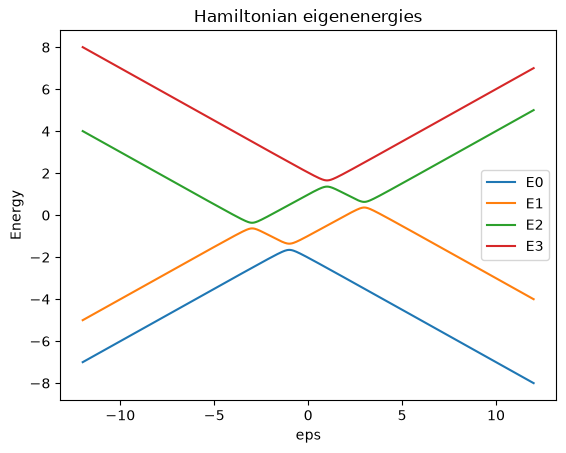

In [3]:
model.plot_eigenvalues();

We solve for the pulse on a dense grid, because the optimized ramp is very steep at the start, and rescale it to the optimized duration:

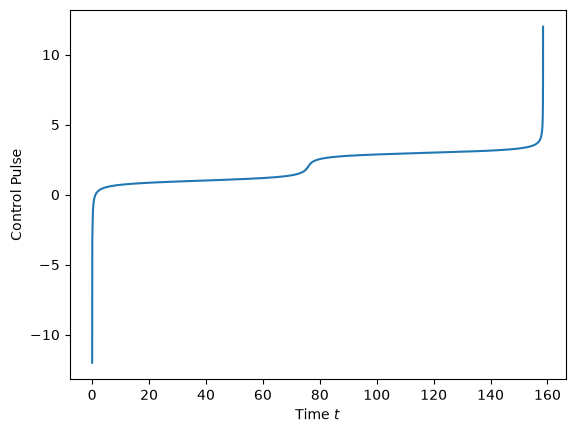

In [4]:
model.solve_problem(pulse_accuracy=20000)

pulse = model.synthesize_pulse(duration=duration)
pulse.plot_pulse();

# Time dynamics

The state-transfer infidelity of the optimized pulse is compared with that of the reference linear ramp (all four exponents zero, $\Delta_L t_\text{f}=500$):

In [5]:
dynamics = gq.Dynamics(model, duration)
print(f"Optimized pulse:      1 - F = {1 - dynamics.state_fidelity():.2e}")

reference = gq.ControlModel(H_d=H_d, H_c=H_c)
reference.set_control(
    control_name="eps",
    pulse_initial=eps0,
    pulse_final=epsf,
    initial_state=1,
    final_state=2,
    alpha=0,
    beta=0,
    dia_alpha=0,
    dia_beta=0,
)
reference.solve_problem(pulse_accuracy=20000)
print(f"Reference linear ramp: 1 - F = {1 - gq.Dynamics(reference, 500).state_fidelity():.2f}")

Optimized pulse:      1 - F = 5.39e-03
Reference linear ramp: 1 - F = 0.72


The populations of the diabatic states follow the intended sequence: the state keeps its $\ket{L,e}$ character through the diabatic passage, and then moves through $\ket{R,e}$ to $\ket{L,g}$ in the two adiabatic passages. The basis states $\ket{0},\dots,\ket{3}$ in the legend are $\ket{L,e}$, $\ket{L,g}$, $\ket{R,e}$ and $\ket{R,g}$:

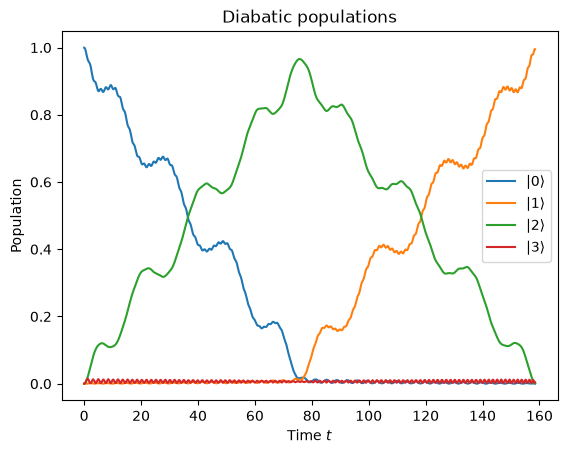

In [6]:
dynamics.plot_populations(basis="diabatic");

About

In [7]:
gq.about()


geodesiq: geometric optimal control
Authors:            Christian Ventura Meinersen & David Fernández Fernández
geodesiq Version:   0.3.0
Python Version:     3.14.6 (cpython)
Number of CPUs:     24
Platform Info:      Windows (11, AMD64)

Core Dependencies:
Numpy Version:      2.4.6
Scipy Version:      1.17.1
QuTiP Version:      5.3.0
Matplotlib Version: 3.11.0

Please cite geodesiq in your publication.
See: https://github.com/geodesiq-control/geodesiq-control#citing-geodesiq
